<a href="https://colab.research.google.com/github/Dyno899/analisis-exo-planetas/blob/main/FinalCorrect_PlanetsDataset_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Código completo en: https://colab.research.google.com/drive/1-lXbB_TgVQkNTT5Zg5xYbH5E73RbRtKa#scrollTo=-_oh_bTrw8sG

La siguiente base de datos se extrajo cuidadosamente y minusiosamente de la "Nasa Exoplanete Archive": https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=PSCompPars
Nos concentramos en la sección: Planetary Sistems Composite Data. Extrajimos información registrada de:
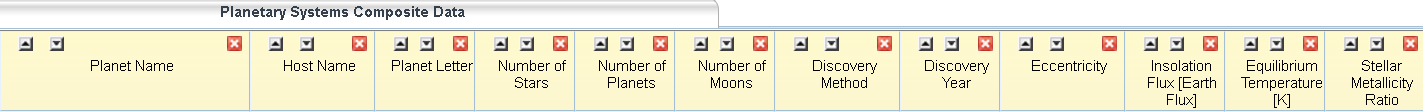

La siguiente información se extrajo de los siguientes sitios especializados:
* 1. Datos Astronómicos (NASA Exoplanet Archive)
Base de datos principal (PSCompPars):

NASA Exoplanet Archive. (2026). Planetary Systems Composite Parameters (PSCompPars) [Data set]. IPAC-Caltech. https://exoplanetarchive.ipac.caltech.edu/

* 2. Paquetes y Funciones de R
Tidyverse (conjunto de paquetes):

Wickham, H., Averick, M., Bryan, J., Chang, W., McGowan, L. D., François, R., ... & Yutani, H. (2019). Welcome to the tidyverse. Journal of Open Source Software, *4*(43), 1686. https://doi.org/10.21105/joss.01686[reference:2]

Ggplot2 (visualización):

Wickham, H. (2016). ggplot2: Elegant Graphics for Data Analysis (2nd ed.). Springer-Verlag. https://doi.org/10.1007/978-3-319-24277-4[reference:3]

R Core Team (para funciones base como cor.test() y kruskal.test()):

R Core Team. (2026). R: A language and environment for statistical computing. R Foundation for Statistical Computing. https://www.R-project.org/

* 3. Literatura Científica de Respaldo
Sobre la correlación planeta-metalicidad (formación de gigantes):

Fischer, D. A., & Valenti, J. (2005). The planet-metallicity correlation. The Astrophysical Journal, *622*(2), 1102-1117. https://doi.org/10.1086/428383[reference:4]

Sobre metalicidad, excentricidad y dinámica de sistemas (scattering planetario):

Dawson, R. I., & Murray-Clay, R. A. (2013). Giant planets orbiting metal-rich stars show signatures of planet-planet interactions. The Astrophysical Journal Letters, *767*(2), L24. https://doi.org/10.1088/2041-8205/767/2/L24[reference:5]



Nuestra intención es extraer una base de datos de exoplanetas registrados desde el siglo XX hasta la acutalidad. Se han registrados más de seis mil exoplanetas, entonces estos datos registrados están en vanguardia. En la página el usuario puede escoger que datos se quieren recopilar y descargar en formato .csv. Nosotro registramos datos como: nombre de los planetas, distintivos o lo que se conoce como HostNames, número de estrellas, planetas y lunas (en órbita al planeta), método utilizado en el descubrimiento, año en que se descubrió, excentricidad del planeta, flujo de insolación solar, temperatura y metalicidad estelar.
 Una observación preliminar es que a la hora de extraer y cargar el archivo .csv. Nos dimos cuenta que las primeras líneas contienen metadatos, descripciones de las columnas y comentarios, no los encabezados de las tablas en sí mismas (como las de la imágen de arriba). Al cargar el archivo  directamente, R intenta interpretar todo ese texto como si fueran nombres de columnas y datos, lo que genera un caos en la visualización.
Así que se propuso la siguiente solución:

Usamos el paquete "readr" para un mayor control de los metadatos registrados. Como se sabe, el paquete readr es parte del tidyverse, para a la hora de importar nuestro archivo .csv, se lea el archivo saltando las líneas con comentarios y las primeras filas, ignorando  las líneas que empiezan con "#" y saltandose las primeras 13 líneas. Método que no interrumpe ni omite información importante de nuestra dataframe.

In [ ]:
install.packages("tidyverse")
library(tidyverse)
library(readr)
library(dplyr)
library(ggplot2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
St1 <- read.csv("/content/PSCompPars_2026.07.12_13.54.49.csv",  comment = "#",skip = 13)
head(St1)

,pl_name,hostname,pl_letter,sy_snum,sy_pnum,sy_mnum,discoverymethod,disc_year,pl_orbeccen,pl_orbeccenerr1,⋯,pl_orbeccenlim,pl_eqt,pl_eqterr1,pl_eqterr2,pl_eqtlim,st_met,st_meterr1,st_meterr2,st_metlim,st_metratio
,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<dbl>,<dbl>,⋯,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>,<chr>
1,11 Com b,11 Com,b,2,1,0,Radial Velocity,2007,0.2380,0.0070,⋯,0,803.26,NA,NA,0,-0.26,0.10,-0.10,0,[Fe/H]
2,11 UMi b,11 UMi,b,1,1,0,Radial Velocity,2009,0.0800,0.0300,⋯,0,896.43,48.40,-48.40,0,-0.02,NA,NA,0,[Fe/H]
3,14 And b,14 And,b,1,1,0,Radial Velocity,2008,0.0000,NA,⋯,0,909.92,NA,NA,0,-0.21,0.10,-0.10,0,[Fe/H]
4,14 Her b,14 Her,b,1,2,0,Radial Velocity,2002,0.3683,0.0029,⋯,0,147.32,1.48,-1.48,0,0.43,0.07,-0.07,0,[Fe/H]
5,16 Cyg B b,16 Cyg B,b,3,1,0,Radial Velocity,1996,0.6800,0.0200,⋯,0,228.76,2.32,-2.32,0,0.06,NA,NA,0,[Fe/H]
6,17 Sco b,17 Sco,b,1,1,0,Radial Velocity,2020,0.0600,0.0300,⋯,0,847.51,13.90,-13.90,0,-0.01,0.10,-0.10,0,[Fe/H]


Lo siguiente que haremos es verificar si existen 'st_met' o 'st_metfe', esto no está del todo claro en la base de datos de la NASA. Estos son lo valores de  una cadena de texto (flag) que indica qué tipo de cociente de metales se midió (puede ser [Fe/H], [M/H], [Mg/H], etc.). El verdadero valor numérico de [Fe/H]  está presente en los nombres de las columnas, esto lo necesitaremos más adelante para ver la relación entre la metalicidad estelar y la excentricidad planetaria.

In [ ]:
print(colnames(St1))

if ("st_met" %in% colnames(St1)) {
  print("La columna 'st_met' existe en St1.")
} else {
  print("La columna 'st_met' NO existe en St1.")
}

if ("st_metfe" %in% colnames(St1)) {
  print("La columna 'st_metfe' existe en St1.")
} else {
  print("La columna 'st_metfe' NO existe en St1.")
}


 [1] "pl_name"         "hostname"        "pl_letter"       "sy_snum"        
 [5] "sy_pnum"         "sy_mnum"         "discoverymethod" "disc_year"      
 [9] "pl_orbeccen"     "pl_orbeccenerr1" "pl_orbeccenerr2" "pl_orbeccenlim" 
[13] "pl_eqt"          "pl_eqterr1"      "pl_eqterr2"      "pl_eqtlim"      
[17] "st_met"          "st_meterr1"      "st_meterr2"      "st_metlim"      
[21] "st_metratio"    
[1] "La columna 'st_met' existe en St1."
[1] "La columna 'st_metfe' NO existe en St1."


Vemos que si existe la columna 'st_met' existe en St1. Es importante porque tiene las mediiones numéricas de la metalicidad estelar.

Como vemos, tenemos una extensa tabla con datos registrados y celdas vacías o con NA's. Vamos a aplicar una limpieza estilo formato Tidyverse.

In [ ]:
St1

pl_name,hostname,pl_letter,sy_snum,sy_pnum,sy_mnum,discoverymethod,disc_year,pl_orbeccen,pl_orbeccenerr1,⋯,pl_orbeccenlim,pl_eqt,pl_eqterr1,pl_eqterr2,pl_eqtlim,st_met,st_meterr1,st_meterr2,st_metlim,st_metratio
<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<dbl>,<dbl>,⋯,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<int>,<chr>
11 Com b,11 Com,b,2,1,0,Radial Velocity,2007,0.2380,0.0070,⋯,0,803.26,NA,NA,0,-0.260,0.10,-0.10,0,[Fe/H]
11 UMi b,11 UMi,b,1,1,0,Radial Velocity,2009,0.0800,0.0300,⋯,0,896.43,48.40,-48.40,0,-0.020,NA,NA,0,[Fe/H]
14 And b,14 And,b,1,1,0,Radial Velocity,2008,0.0000,NA,⋯,0,909.92,NA,NA,0,-0.210,0.10,-0.10,0,[Fe/H]
14 Her b,14 Her,b,1,2,0,Radial Velocity,2002,0.3683,0.0029,⋯,0,147.32,1.48,-1.48,0,0.430,0.07,-0.07,0,[Fe/H]
16 Cyg B b,16 Cyg B,b,3,1,0,Radial Velocity,1996,0.6800,0.0200,⋯,0,228.76,2.32,-2.32,0,0.060,NA,NA,0,[Fe/H]
17 Sco b,17 Sco,b,1,1,0,Radial Velocity,2020,0.0600,0.0300,⋯,0,847.51,13.90,-13.90,0,-0.010,0.10,-0.10,0,[Fe/H]
18 Del b,18 Del,b,2,1,0,Radial Velocity,2008,0.0240,0.0070,⋯,0,452.72,NA,NA,0,-0.060,0.10,-0.10,0,[Fe/H]
1RXS J160929.1-210524 b,1RXS J160929.1-210524,b,1,1,0,Imaging,2008,NA,NA,⋯,NA,1700.00,100.00,-100.00,0,NA,NA,NA,NA,
24 Boo b,24 Boo,b,1,1,0,Radial Velocity,2018,0.0320,0.0390,⋯,0,1840.86,NA,NA,0,-0.780,0.10,-0.10,0,[Fe/H]


Visualicemos que tenemos:

In [ ]:
glimpse(St1)

Rows: 6,319
Columns: 21
$ pl_name         <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "16 Cy…
$ hostname        <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B", "1…
$ pl_letter       <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "b", "c",…
$ sy_snum         <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, …
$ sy_pnum         <int> 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, …
$ sy_mnum         <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ discoverymethod <chr> "Radial Velocity", "Radial Velocity", "Radial Velocity…
$ disc_year       <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2008, 2018, …
$ pl_orbeccen     <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.0240…
$ pl_orbeccenerr1 <dbl> 0.0070, 0.0300, NA, 0.0029, 0.0200, 0.0300, 0.0070, NA…
$ pl_orbeccenerr2 <dbl> -0.0070, -0.0300, NA, -0.0029, -0.0200, -0.0200, -0.01…
$ pl_orbeccenlim  <int> 0, 0, 0, 0, 0, 0, 0, NA, 0, 0, 0, NA, NA, NA, NA, NA, …
$ pl_eqt        

Nuestro interés ahora será quitar aquellas columnas que no aportan información. A nivel técnico son mediciones inconclusas en la medición estelar. Una regla de oro en Astrofísica es: Una NA significa "no se midió" o "no está disponible". Reemplazarlo por 0 siempre introduce un sesgo, porque 0 es un valor físico real en muchas de estas variables (ej: excentricidad = 0 es una órbita perfectamente circular; metalicidad = 0 es exactamente la del Sol).
Aquí tomaremos dos caminos distintos:

Primer camino (columnas donde se dejarán las NA's y filtrar):

*   Para pl_orbeccen (Excentricidad): Sus Na's no las vamos a reempazalar  por 0. Ya que fueron cosas que no se medieron.

* Para st_met (Metalicidad numérica)Sus NA's tampoco van a ser reeplazadas por 0.
* Para  pl_orbeccenerr1/2 y st_meterr1/2 (Errores): los vamos a dejar  como NA. No los necesitamos por el momento. Reemplazarlos por 0 implicaría que la medición tiene error cero (lo cual es físicamente imposible). Podríamos incluso  borrar estas columnas.

Segundo camino (columnas para reemplazar las NA's por ceros):

* Variables de conteo como sy_snum (Número de estrellas) o sy_pnum (Número de planetas) poner 0 podría tener sentido lógico (podría ser que no se encontraron estrellas/planetas)


Para esto usaremos la función select () del tidyverse.

En la visualización de nuestra tabla tenemos errores absolutos incluidas en las mediciones. Por ejemplo un valor de la excentricidad se presenta como
0.238±0.007. En el Glimpse() anterior corresponde a la varibale "pl_orbeccen" y los valores decimales + 0.007 y - 0.007 se presentan como otras varibales llamadas: pl_orbeccenerr1 y pl_orbeccenerr2 respectivamente. De momento las vamos a quitar,  ya que nuestra intención más adelante será mostrar gráficos estadísticos que nos indiquen comportamientos impotantes sobre los valores numéricos en principio. A continuación una imágen de la tabla en la página para tener más clara la explicación.
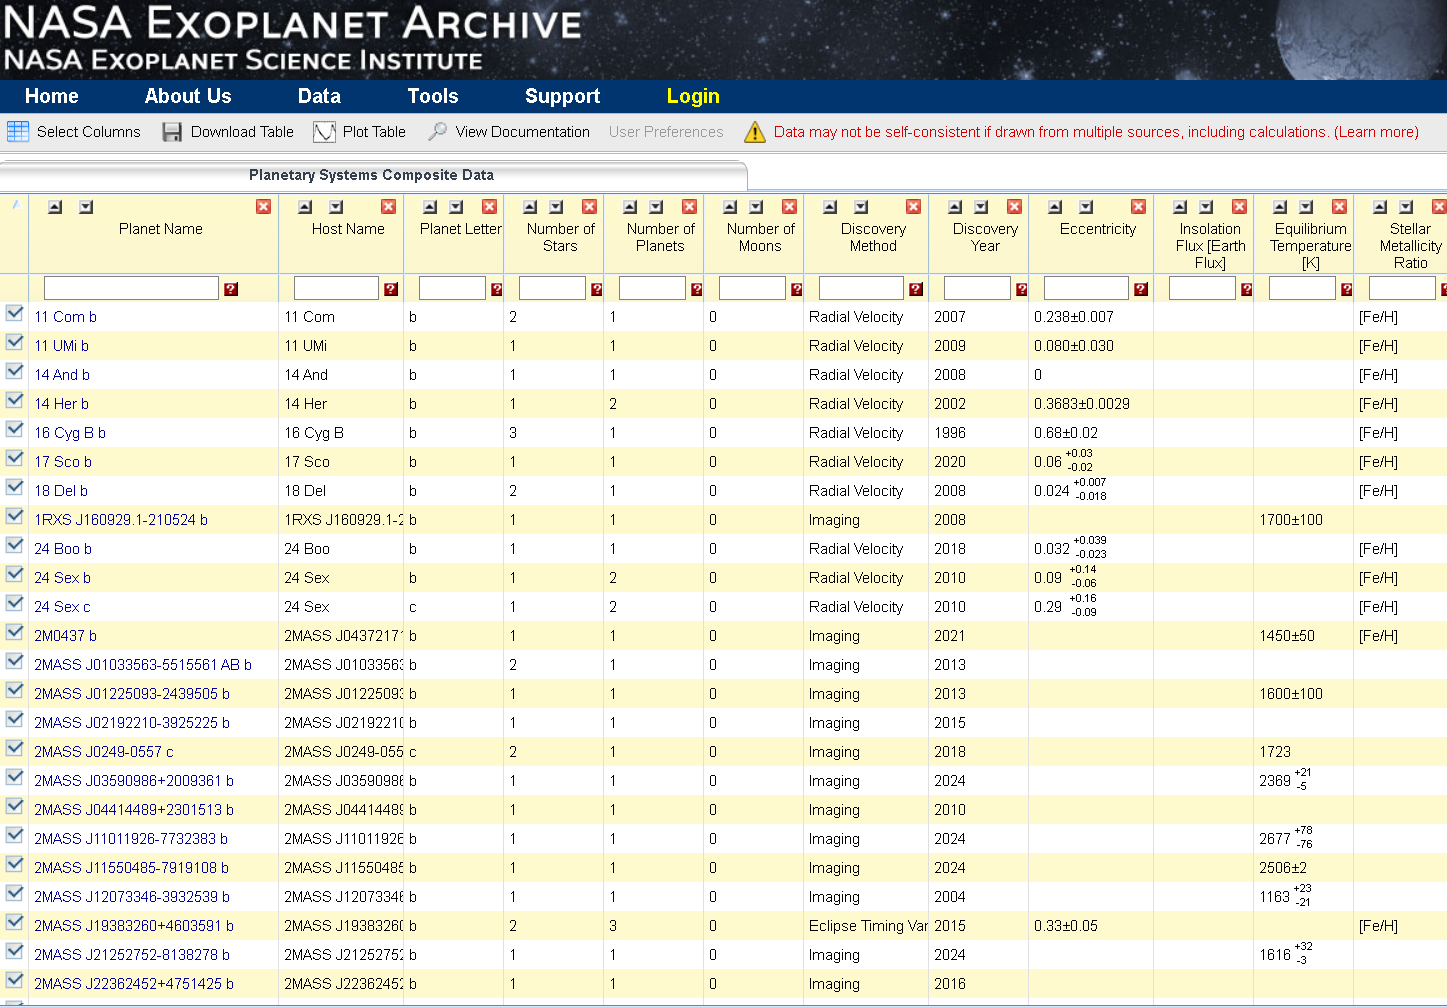


In [ ]:
St2 <- St1 %>%
select(-pl_orbeccenerr1, -pl_orbeccenerr2,
-pl_eqterr1, -pl_eqterr2,
-st_meterr1, -st_meterr2)
glimpse(St2)

Rows: 6,319
Columns: 15
$ pl_name         <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "16 Cy…
$ hostname        <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B", "1…
$ pl_letter       <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "b", "c",…
$ sy_snum         <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, …
$ sy_pnum         <int> 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, …
$ sy_mnum         <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ discoverymethod <chr> "Radial Velocity", "Radial Velocity", "Radial Velocity…
$ disc_year       <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2008, 2018, …
$ pl_orbeccen     <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.0240…
$ pl_orbeccenlim  <int> 0, 0, 0, 0, 0, 0, 0, NA, 0, 0, 0, NA, NA, NA, NA, NA, …
$ pl_eqt          <dbl> 803.26, 896.43, 909.92, 147.32, 228.76, 847.51, 452.72…
$ pl_eqtlim       <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, NA, 0, 0, 0, 0, 0,…
$ st_met        

Ahora, para facilitar la lectura de la tabla, vamos a renombras las variables usando la función rename() y vamos a visualizar posteriormente con glimpse () que tenemos.

In [ ]:
St3 <- St2 %>%
rename(
Nombre = pl_name,
Host = hostname,
Distintivo = pl_letter,
Número_Estrellas = sy_snum,
Número_Planetas = sy_pnum,
Número_Lunas = sy_mnum,
Método = discoverymethod,
Año_descubrimiento = disc_year,
Excentricidad = pl_orbeccen,
 FlagExcentricidad =pl_orbeccenlim,
Flujo_Solar = pl_eqt,
FlagFlujo = pl_eqtlim,
Valor_Metalicidad = st_met,
FlagMetalicidad = st_metlim,
 Metalicidad_Estelar =  st_metratio
  )
glimpse(St3)

Rows: 6,319
Columns: 15
$ Nombre              <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "1…
$ Host                <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B"…
$ Distintivo          <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "b", …
$ Número_Estrellas    <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1,…
$ Número_Planetas     <int> 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1,…
$ Número_Lunas        <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Método              <chr> "Radial Velocity", "Radial Velocity", "Radial Velo…
$ Año_descubrimiento  <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2008, 20…
$ Excentricidad       <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.…
$ FlagExcentricidad   <int> 0, 0, 0, 0, 0, 0, 0, NA, 0, 0, 0, NA, NA, NA, NA, …
$ Flujo_Solar         <dbl> 803.26, 896.43, 909.92, 147.32, 228.76, 847.51, 45…
$ FlagFlujo           <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, NA, 0, 0, 0, 0…
$ Valor_Metalici

Cabe mencionar que el numéro de estrellas corresponde precisamente a las estrellas en órbita al rededor del planeta.

Observación:
 ¿Qué son las columnas lim (ej: pl_orbeccenlim)?
No son errores. como tal son banderas de calidad (flags) que indican cómo se obtuvo ese número:

* lim = 0 → Valor medido directamente (el dato es fiable, es una publicación directa).

* lim = 1 (o mayor) → Es un límite superior (ej: "la excentricidad es menor a 0.1"), no un valor exacto.

* lim = NA → No se especificó o no aplica.

No borramos  estas columnas pues usaremos  lim == 0 para filtrar y quedarnos  solo con los datos de alta calidad.

In [ ]:
# Veamos  los valores únicos de la columna de límite de excentricidad
table(St3$FlagExcentricidad)

# Veamos los valores únicos de la columna de límite de metalicidad
table(St3$FlagMetalicidad)


  -1    0    1 
  11 4969  286 


  -1    0    1 
   2 5675    2 

In [ ]:
# Filtrado para quedarnos SOLO con filas donde la excentricidad Y la metalicidad sean mediciones directas (lim == 0)
st4 <- St3 %>%
filter(FlagExcentricidad == 0 & FlagMetalicidad  == 0)
glimpse(st4)

Rows: 4,848
Columns: 15
$ Nombre              <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "1…
$ Host                <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B"…
$ Distintivo          <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "c", …
$ Número_Estrellas    <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 3, 2,…
$ Número_Planetas     <int> 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 3, 1, 3, 3, 3, 1, 7,…
$ Número_Lunas        <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Método              <chr> "Radial Velocity", "Radial Velocity", "Radial Velo…
$ Año_descubrimiento  <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2018, 20…
$ Excentricidad       <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.…
$ FlagExcentricidad   <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Flujo_Solar         <dbl> 803.26, 896.43, 909.92, 147.32, 228.76, 847.51, 45…
$ FlagFlujo           <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Valor_Metalici

In [ ]:
st5<- st4%>%
  filter(!is.na(Excentricidad),   # Quitamos filas donde Excentricidad sea NA
  !is.na(Valor_Metalicidad))     # Quitamos filas donde Metalicidad sea NA
  #Hacemos esto porque todavía puedemos tener NA en Excentricidad o Metalicidad (porque puede que la medición tenga lim=0 pero el valor numérico sea NA por error en la tabla).
  glimpse(st5)

Rows: 4,848
Columns: 15
$ Nombre              <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "1…
$ Host                <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B"…
$ Distintivo          <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "c", …
$ Número_Estrellas    <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 3, 2,…
$ Número_Planetas     <int> 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 3, 1, 3, 3, 3, 1, 7,…
$ Número_Lunas        <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Método              <chr> "Radial Velocity", "Radial Velocity", "Radial Velo…
$ Año_descubrimiento  <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2018, 20…
$ Excentricidad       <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.…
$ FlagExcentricidad   <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Flujo_Solar         <dbl> 803.26, 896.43, 909.92, 147.32, 228.76, 847.51, 45…
$ FlagFlujo           <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Valor_Metalici

In [ ]:
#Verificamos que no hay NA's en FlagExcentricidad y FlagMetalicidad
st5 %>%
summarise(
NA_FlagExcentricidad = sum(is.na(FlagExcentricidad)),
NA_FlagMetalicidad = sum(is.na(FlagMetalicidad))
)
glimpse(st5)

NA_FlagExcentricidad,NA_FlagMetalicidad
<int>,<int>
0,0


Rows: 4,848
Columns: 15
$ Nombre              <chr> "11 Com b", "11 UMi b", "14 And b", "14 Her b", "1…
$ Host                <chr> "11 Com", "11 UMi", "14 And", "14 Her", "16 Cyg B"…
$ Distintivo          <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "c", …
$ Número_Estrellas    <int> 2, 1, 1, 1, 3, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 3, 2,…
$ Número_Planetas     <int> 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 3, 1, 3, 3, 3, 1, 7,…
$ Número_Lunas        <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Método              <chr> "Radial Velocity", "Radial Velocity", "Radial Velo…
$ Año_descubrimiento  <int> 2007, 2009, 2008, 2002, 1996, 2020, 2008, 2018, 20…
$ Excentricidad       <dbl> 0.2380, 0.0800, 0.0000, 0.3683, 0.6800, 0.0600, 0.…
$ FlagExcentricidad   <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Flujo_Solar         <dbl> 803.26, 896.43, 909.92, 147.32, 228.76, 847.51, 45…
$ FlagFlujo           <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Valor_Metalici

La visualización anterior dada con Glimpse() podemos ver que los criteriors del formato data se cumplen, excepto uno, vamos en orden:

*   Cada varibale está en su columna
*   Cada observación en la fila correspondiente



In [ ]:
sum(is.na(st5))

[1] 88

Como vemos ya no tenemos NA's.
Lo siguiente que nos interesa hacer es usar la función arrange() para ordenar  las filas según los valores de una o más columnas, de forma ascendente. Específicamente de los valores numéricos.

In [ ]:
St6 <- st5 %>%
arrange(Número_Estrellas,  Número_Planetas,Número_Lunas,  Año_descubrimiento,  Excentricidad, Flujo_Solar, Valor_Metalicidad)
glimpse(St6)


Rows: 4,848
Columns: 15
$ Nombre              <chr> "70 Vir b", "HD 210277 b", "HD 209458 b", "HD 1303…
$ Host                <chr> "70 Vir", "HD 210277", "HD 209458", "HD 130322", "…
$ Distintivo          <chr> "b", "b", "b", "b", "b", "b", "b", "b", "b", "b", …
$ Número_Estrellas    <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ Número_Planetas     <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ Número_Lunas        <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Método              <chr> "Radial Velocity", "Radial Velocity", "Radial Velo…
$ Año_descubrimiento  <int> 1996, 1998, 1999, 1999, 1999, 1999, 1999, 2000, 20…
$ Excentricidad       <dbl> 0.3988, 0.4800, 0.0000, 0.0290, 0.0500, 0.1040, 0.…
$ FlagExcentricidad   <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Flujo_Solar         <dbl> 525.24, 259.86, 1459.00, 720.00, 486.00, 259.25, 3…
$ FlagFlujo           <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ Valor_Metalici

A continuación, de momento quitaremos las columnas con valores de caracteres

In [ ]:
St7 <-St6 %>%
select(-Nombre,-Host, -Distintivo,-Método,-Metalicidad_Estelar)
glimpse(St7)

Rows: 4,848
Columns: 10
$ Número_Estrellas   <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ Número_Planetas    <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ Número_Lunas       <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ Año_descubrimiento <int> 1996, 1998, 1999, 1999, 1999, 1999, 1999, 2000, 200…
$ Excentricidad      <dbl> 0.3988, 0.4800, 0.0000, 0.0290, 0.0500, 0.1040, 0.1…
$ FlagExcentricidad  <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ Flujo_Solar        <dbl> 525.24, 259.86, 1459.00, 720.00, 486.00, 259.25, 32…
$ FlagFlujo          <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ Valor_Metalicidad  <dbl> -0.0900, 0.2200, 0.0100, -0.0200, 0.0300, 0.1700, 0…
$ FlagMetalicidad    <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


Vamos a calcular estadísticos descriptivos (media, mediana, cuartiles, etc.) Para obtener un resumen global de las variables. Usaremos la función: na.rm = TRUE para poder usar las funciones estadísticas, ya que queremos un resumen para cada una de las anteriores variables y luego generar un gráfico comparativo. Como queremos las  mismas estadística para las columnas, usaremos across(): Al hacer summarise(across(...)), las funciones como mean(), sd(), min(), etc., se aplican a cada columna seleccionada. Además  everything() nos ayuda para no escribir nombre por nombre. Antes de esto, eliminaremos las siguientes columnas, ya que no nos aportarán mucho para lo que queremos hacer.

In [ ]:
St8 <- St7 %>%
  select(-FlagExcentricidad, -FlagFlujo, -FlagMetalicidad)
glimpse(St8)

Rows: 4,848
Columns: 7
$ Número_Estrellas   <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ Número_Planetas    <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ Número_Lunas       <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ Año_descubrimiento <int> 1996, 1998, 1999, 1999, 1999, 1999, 1999, 2000, 200…
$ Excentricidad      <dbl> 0.3988, 0.4800, 0.0000, 0.0290, 0.0500, 0.1040, 0.1…
$ Flujo_Solar        <dbl> 525.24, 259.86, 1459.00, 720.00, 486.00, 259.25, 32…
$ Valor_Metalicidad  <dbl> -0.0900, 0.2200, 0.0100, -0.0200, 0.0300, 0.1700, 0…


In [ ]:
St9<- St8 %>%
summarise(
across(
everything(),   # Dado que escogí solo las columnas con valores numéricoS
list(
media       = ~mean(.x, na.rm = TRUE),
mediana     = ~median(.x, na.rm = TRUE),
sd          = ~sd(.x, na.rm = TRUE),
suma        = ~sum(.x, na.rm = TRUE),
n_distintos = ~n_distinct(.x),
min         = ~min(.x, na.rm = TRUE),
max         = ~max(.x, na.rm = TRUE),
Q1          = ~quantile(.x, 0.25, na.rm = TRUE),
Q3          = ~quantile(.x, 0.75, na.rm = TRUE)
),
.names = "{.col}_{.fn}"
)
)
glimpse(St9)

Rows: 1
Columns: 63
$ Número_Estrellas_media         <dbl> 1.101691
$ Número_Estrellas_mediana       <dbl> 1
$ Número_Estrellas_sd            <dbl> 0.3389525
$ Número_Estrellas_suma          <int> 5341
$ Número_Estrellas_n_distintos   <int> 4
$ Número_Estrellas_min           <int> 1
$ Número_Estrellas_max           <int> 4
$ Número_Estrellas_Q1            <dbl> 1
$ Número_Estrellas_Q3            <dbl> 1
$ Número_Planetas_media          <dbl> 1.828177
$ Número_Planetas_mediana        <dbl> 1
$ Número_Planetas_sd             <dbl> 1.184616
$ Número_Planetas_suma           <int> 8863
$ Número_Planetas_n_distintos    <int> 8
$ Número_Planetas_min            <int> 1
$ Número_Planetas_max            <int> 8
$ Número_Planetas_Q1             <dbl> 1
$ Número_Planetas_Q3             <dbl> 2
$ Número_Lunas_media             <dbl> 0
$ Número_Lunas_mediana           <dbl> 0
$ Número_Lunas_sd                <dbl> 0
$ Número_Lunas_suma              <int> 0
$ Número_Lunas_n_distintos       <int> 1
$ 

Como vemos, esto nos  devolvió  una sola fila con todas las estadísticas de cada variable:



In [ ]:
St9

Número_Estrellas_media,Número_Estrellas_mediana,Número_Estrellas_sd,Número_Estrellas_suma,Número_Estrellas_n_distintos,Número_Estrellas_min,Número_Estrellas_max,Número_Estrellas_Q1,Número_Estrellas_Q3,Número_Planetas_media,⋯,Flujo_Solar_Q3,Valor_Metalicidad_media,Valor_Metalicidad_mediana,Valor_Metalicidad_sd,Valor_Metalicidad_suma,Valor_Metalicidad_n_distintos,Valor_Metalicidad_min,Valor_Metalicidad_max,Valor_Metalicidad_Q1,Valor_Metalicidad_Q3
<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1.101691,1,0.3389525,5341,4,1,4,1,1,1.828177,⋯,1066,0.02128038,0.03,0.1853769,103.1673,517,-1,0.79,-0.07,0.1381


Aquí es cuando necesitamos pasar a formato largo (Tidy) y luego seleccionar los estadísticos que vamos  representar. También usaremos la función separate () y   como el texto tiene más fragmentos de los que caben en into, necesitamos saber  qué hacer con los sobrantes. Enconces usaremos en su argumento final: extra = "merge".

In [ ]:
St10 <- St9 %>%
pivot_longer(
cols = everything(),
names_to = "variable_estadistico",
values_to = "valor")
# Aquí separo la columna "variable_estadistico" en "variable" y "estadistico"
St11<- St10 %>%
separate(variable_estadistico, into = c("variable", "estadistico"), sep = "_(?!.*_)", extra = "merge")

Usamos la función Filter () para  filtrar y ver algunos resultados:

In [ ]:
St11 %>% filter(variable == "Excentricidad") %>% print()

# A tibble: 8 × 3
  variable      estadistico    valor
  <chr>         <chr>          <dbl>
1 Excentricidad media         0.0705
2 Excentricidad mediana       0     
3 Excentricidad sd            0.148 
4 Excentricidad suma        342.    
5 Excentricidad min           0     
6 Excentricidad max           0.95  
7 Excentricidad Q1            0     
8 Excentricidad Q3            0.07  


In [ ]:
St11 %>% filter(variable == "Año_descubrimiento") %>% print()

# A tibble: 8 × 3
  variable           estadistico      valor
  <chr>              <chr>            <dbl>
1 Año_descubrimiento media          2016.  
2 Año_descubrimiento mediana        2016   
3 Año_descubrimiento sd                4.90
4 Año_descubrimiento suma        9775350   
5 Año_descubrimiento min            1996   
6 Año_descubrimiento max            2026   
7 Año_descubrimiento Q1             2014   
8 Año_descubrimiento Q3             2020   


Queremos ahora analizar la distribución de los datos para excentricidad con un diagrama de violín. Esto lo hacemos porque estas dos mediciones son centrales en nuestra investigación.


    Excentricidad Valor_Metalicidad 
             4848              4848 

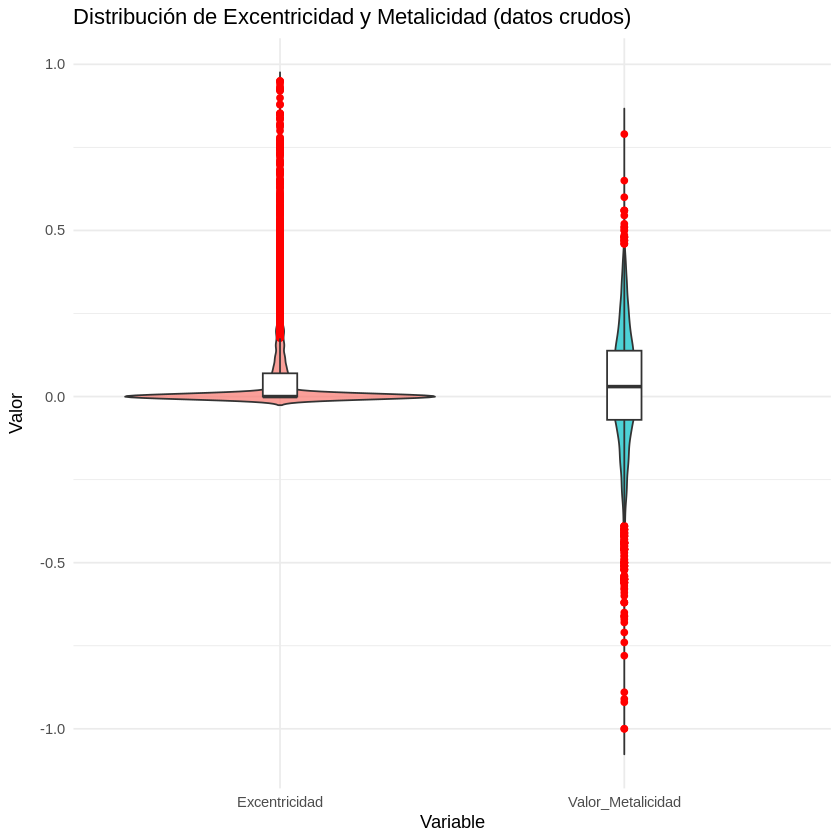

In [ ]:
masa <- read.csv("/content/PSCompPars_2026.07.13_02.53.43.csv",
  comment = "#", skip = 13)

# Renombramos las columnas de la tabla 'masa'
colnames(masa) <- c("Nombre", "Masa_Jupiter", "Masa_err1", "Masa_err2", "FlagMasa")

# Filtramos solo los datos de calidad (lim == 0) y sin NA
masa_clean <- masa %>%
filter(FlagMasa == 0, !is.na(Masa_Jupiter)) %>%
select(Nombre, Masa_Jupiter)

# Unimos con el dataframe principal 'st5' (asumiendo st5 está definido previamente)
datos_completos <- st5 %>%
 left_join(masa_clean, by = "Nombre")

# Seleccionamos las columnas de interés y las ponemos en formato largo
datos_violin <- datos_completos %>%
  select(Excentricidad, Valor_Metalicidad) %>%
  pivot_longer(cols = everything(), names_to = "Variable", values_to = "Valor") %>%
  filter(!is.na(Valor))

# Vemos  cuántos datos tiene cada variable
table(datos_violin$Variable)

#  Graficar violín con boxplot superpuesto

ggplot(datos_violin, aes(x = Variable, y = Valor, fill = Variable)) +
geom_violin(trim = FALSE, alpha = 0.7) +
geom_boxplot(width = 0.1, fill = "white", outlier.color = "red") +
labs(title = "Distribución de Excentricidad y Metalicidad (datos crudos)",
x = "Variable", y = "Valor") +
theme_minimal() +
theme(legend.position = "none") +
scale_y_continuous(breaks = seq(-1, 1, by = 0.5))

Aquí hay una cuestión importante: En el gráfico anterior, el eje Y va de 0.0 a 1.0.

El problema es que la metalicidad ([Fe/H]) tiene valores negativos. Al forzar el eje Y a empezar en 0, se  corta toda la mitad negativa de la distribución de metalicidad.

Por eso el diagrama se ve raro. Necesitamos una escala libre con una función llamada:facet_wrap()
Para ver correctamente ambas distribuciones, cada una debe tener su propia escala en el eje Y.

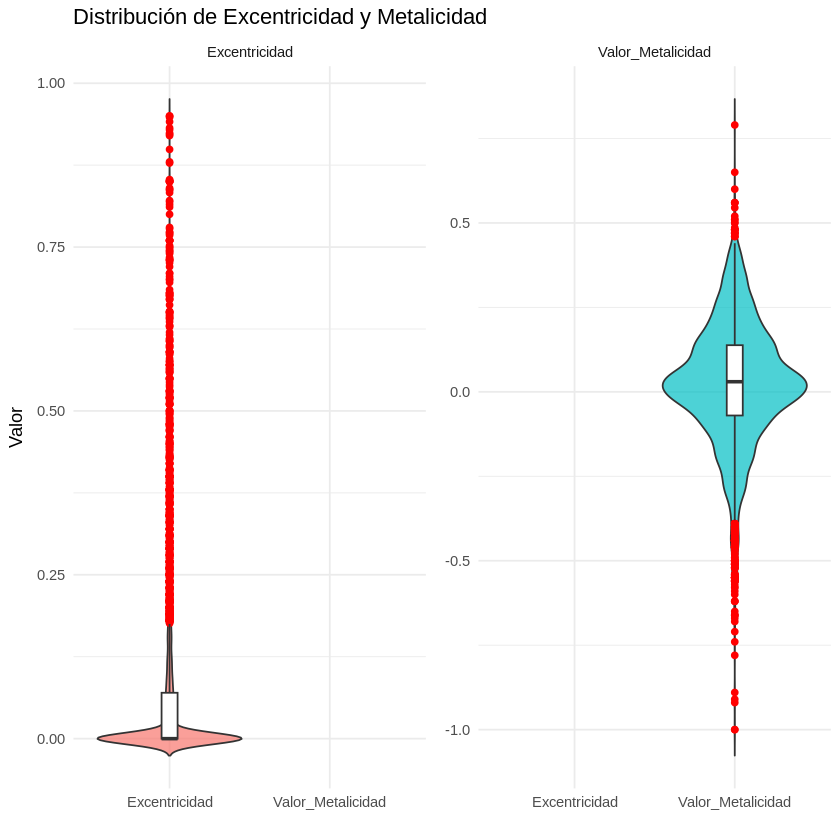

In [ ]:

datos_violin <- datos_completos %>%
  select(Excentricidad, Valor_Metalicidad) %>%
  pivot_longer(cols = everything(), names_to = "Variable", values_to = "Valor") %>%
  filter(!is.na(Valor))

ggplot(datos_violin, aes(x = Variable, y = Valor, fill = Variable)) +
  geom_violin(trim = FALSE, alpha = 0.7) +
  geom_boxplot(width = 0.1, fill = "white", outlier.color = "red") +
  facet_wrap(~ Variable, scales = "free_y") +   # Función para la escala libre
  labs(title = "Distribución de Excentricidad y Metalicidad ",
  x = "", y = "Valor") +
  theme_minimal() +
  theme(legend.position = "none")

Interpretación:
* Un pico  en Excentricidad = 0 (prácticamente una barra vertical en el violín).

Una cola larga y delgada que se extiende desde 0.2 hasta 0.95 (casi 1).
La mayoría de los puntos están concentrados en valores muy cercanos a 0.
Durante la formación planetaria en un disco protoplanetario, los planetas interactúan con el gas y el polvo. La fricción con el disco amortigua las excentricidades y las circulariza (reduce la excentricidad a casi 0).
Por eso, la gran mayoría de los planetas recién formados tienen órbitas casi circulares, como los planetas de nuestro Sistema Solar (todos tienen excentricidades < 0.1, excepto Mercurio con 0.2).

* La cola larga: planetas que han sido "perturbados"
La cola hacia valores altos (e > 0.3) representa una subpoblación  activa. Estos planetas han experimentado interacciones gravitacionales violentas que excitaron sus excentricidades (según la documentación que encontre):
El Scattering planetario es cuando dos o más planetas gigantes interactúan gravitacionalmente, uno puede ser expulsado o lanzado a una órbita muy excéntrica.
La correlación Masa vs Excentricidad (ρ = 0.548) demuestra que los planetas más masivos son precisamente los que ocupan esa cola. Los gigantes gaseosos son los que experimentan scattering y se vuelven excéntricos.

* La forma del violín (sesgo positivo)
La distribución tiene un sesgo fuerte a la derecha (media > mediana). En las estadísticas, la mediana es 0, pero la media es 0.066. Esto indica que, aunque la mayoría son circulares, la cola de altas excentricidades "tira" del promedio hacia arriba. Este sesgo es característico de poblaciones donde hay un proceso físico (el scattering que escribí arriba) que afecta a una minoría.

* Distribución de la Metalicidad [Fe/H] (panel derecho)
Tenemos una distribución en forma de campana (aproximadamente normal), centrada alrededor de 0 (el valor del Sol).

* Un sesgo positivo (más valores > 0 que < -0.5). La cola hacia la derecha es más larga que hacia la izquierda. El rango va de aproximadamente -0.8 a +0.6.
La mayoría de las estrellas con planetas detectados tienen una metalicidad similar a la del Sol ([Fe/H] ≈ 0). Esto refleja que el Sol es una estrella de población I (como lo mencionaré más adelante) y que los métodos de detección han favorecido estrellas de este tipo.

* El sesgo positivo: el "sesgo de metalicidad"
Hay más estrellas con [Fe/H] > 0 que con [Fe/H] < -0.3. Esto es el famoso "sesgo de metalicidad" descubierto por Fischer & Valenti (2005) y confirmado por muchos estudios posteriores, esto se puede ver facilmente en la documentación. -

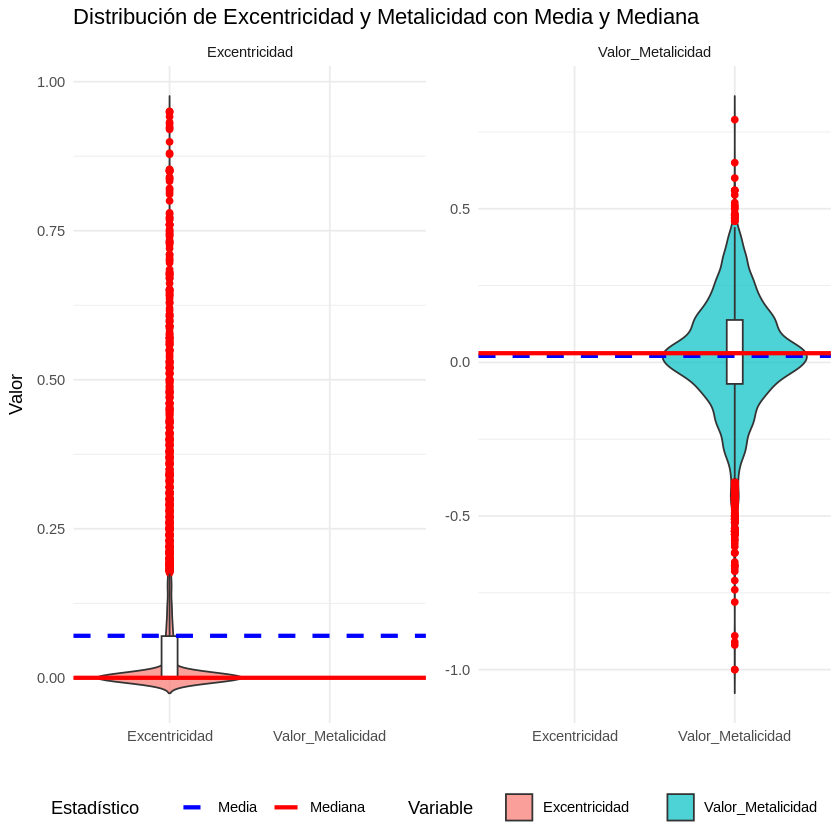

In [ ]:
library(dplyr)
library(tidyr)

masa <- read.csv("/content/PSCompPars_2026.07.13_02.53.43.csv",
  comment = "#", skip = 13)

colnames(masa) <- c("Nombre", "Masa_Jupiter", "Masa_err1", "Masa_err2", "Masa_lim")

masa_clean <- masa %>%
  filter(Masa_lim == 0, !is.na(Masa_Jupiter)) %>%
  select(Nombre, Masa_Jupiter)

datos_completos <- st5 %>%
  left_join(masa_clean, by = "Nombre")

datos_violin <- datos_completos %>%
  select(Excentricidad, Valor_Metalicidad) %>%
  pivot_longer(cols = everything(), names_to = "Variable", values_to = "Valor") %>%
  filter(!is.na(Valor))


stats_summary <- datos_violin %>%
  group_by(Variable) %>%
  summarise(
    Media = mean(Valor, na.rm = TRUE),
    Mediana = median(Valor, na.rm = TRUE)
  )

# Gráfico con líneas de media y mediana
ggplot(datos_violin, aes(x = Variable, y = Valor, fill = Variable)) +
  geom_violin(trim = FALSE, alpha = 0.7) +
  geom_boxplot(width = 0.1, fill = "white", outlier.color = "red") +

  # Línea de la MEDIA (azul discontinua)
  geom_hline(data = stats_summary,
  aes(yintercept = Media, color = "Media"),
  linetype = "dashed", size = 1.2) +

  # Línea de la MEDIANA (roja sólida)
  geom_hline(data = stats_summary,
  aes(yintercept = Mediana, color = "Mediana"), # Corregido el error de sintaxis aquí
  linetype = "solid", size = 1.2) +

  facet_wrap(~ Variable, scales = "free_y") +
  scale_color_manual(name = "Estadístico",
  values = c("Media" = "blue", "Mediana" = "red")) +
  labs(title = "Distribución de Excentricidad y Metalicidad con Media y Mediana",
  x = "", y = "Valor") +
  theme_minimal() +
  theme(legend.position = "bottom")

En las siguientes secciones trataremos de representar y estudiar la relación entre varias varibales.

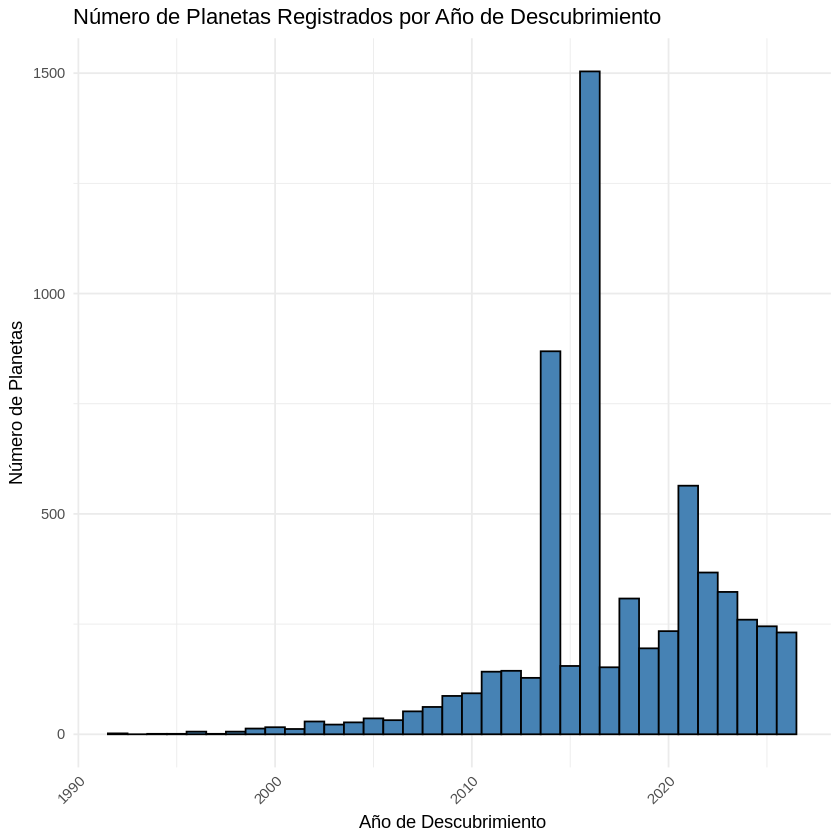

In [ ]:
# Histograma del número de planetas registrados por año de descubrimiento
ggplot(St3, aes(x = Año_descubrimiento)) +
geom_histogram(binwidth = 1, fill = "steelblue", color = "black") +
labs(
title = "Número de Planetas Registrados por Año de Descubrimiento",
x = "Año de Descubrimiento",
y = "Número de Planetas"
) +
theme_minimal() +
theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [ ]:
# Encontrar el año con más planetas descubiertos
#Vamos a agrupar el dataframe St3 por la columna Año_descubrimiento. Esto va prepara los datos para que la operacion subsiguiente se realicen por separado para cada año de descubrimiento único.
año_mas_descubrimientos <- St3 %>%
group_by(Año_descubrimiento) %>%
# Después de agrupar, la siguiente función calcula un resumen para cada grupo. n() es una función que cuenta el número de filas en cada grupo.
summarise(conteo = n()) %>%
#Ordenamos  por la columna conteo en orden descendente, lo que significa que el año con el mayor número de descubrimientos aparecerá primero.
arrange(desc(conteo)) %>%
#La siguiente   función selecciona solo la primera fila del dataframe ya ordenado.
slice(1)
#Accedemos s las columnas:
print(paste("El año con más descubrimientos de planetas es:", año_mas_descubrimientos$Año_descubrimiento, "con", año_mas_descubrimientos$conteo, "planetas."))

[1] "El año con más descubrimientos de planetas es: 2016 con 1504 planetas."


También podemos encontrar el año con menos descubrimientos:

In [ ]:
año_menos_descubrimientos <- St3 %>%
  group_by(Año_descubrimiento) %>%
  summarise(conteo = n()) %>%
  arrange(conteo) %>%
  slice(1)

print(paste("El año con menos descubrimientos es:", año_menos_descubrimientos$Año_descubrimiento, "con", año_menos_descubrimientos$conteo,"planetas"))

[1] "El año con menos descubrimientos es: 1994 con 1 planetas"


Lo siguiente que harémos es análogo a lo inmediatamente anterior. Queremos ahora ver  que método encontró más planetas.

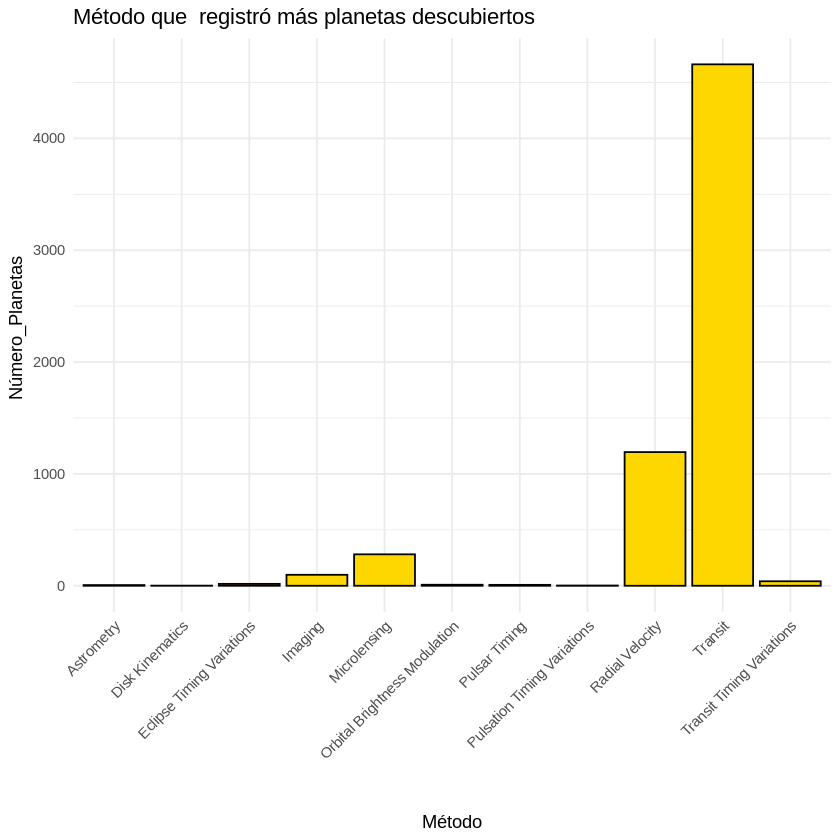

In [ ]:
# Histograma del método que  registró más planetas descubiertos
# Como Método es una variable categórica (discreta), necesitamos usar geom_bar() para contar cuántos planetas fueron descubiertos por cada método
ggplot(St3, aes(x = Método )) +
  geom_bar(fill = "gold", color = "black") +
  labs(
    title = "Método que  registró más planetas descubiertos",
    x = "Método",
    y = "Número_Planetas "
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

Entonces el método de transito fue el más utilizado para el descubrimiento de planetas, lo que lo convierte en el más efectivo en cuanto a detectar planetas midiendo pequeñas disminuciones en el brillo de una estrella; esto sucede cuando el planeta pasa frente a la estrella. Mientras que el menos efectivo o más laborioso fue el Astrométrico, ya que mide el movimiento de una estrella causado por la gravedad del planeta,  lo que requiere mediciones muy precisas, más que otras, lo que lo hace obsoleto.

Metalicidad presente y número de estrellas presentes por planeta

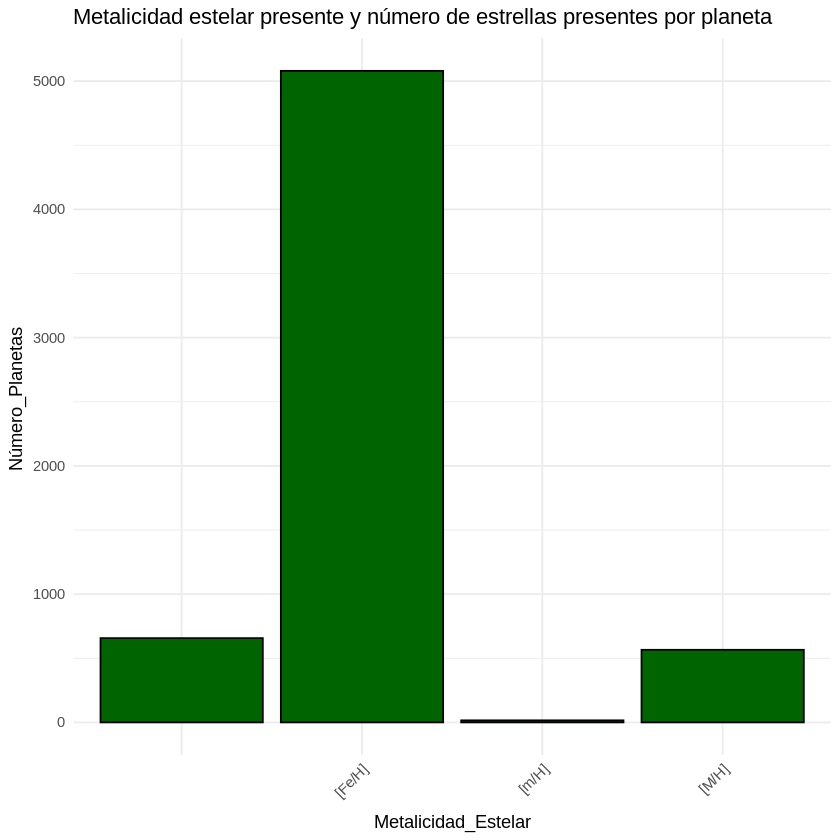

In [ ]:
ggplot(St3, aes(x = Metalicidad_Estelar )) +
  geom_bar(fill = "darkgreen", color = "black") +
  labs(
    title = "Metalicidad estelar presente y número de estrellas presentes por planeta",
    x = "Metalicidad_Estelar",
    y = "Número_Planetas "
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

Este histograma junto con el anterior, sugiere que el método de tránsito y la presencia de  metalicidad estelar como la del cociente  Fe/H son indicadores irrefutables para encontrar exoplanetas en tipos de estrellas muy particulares.
También este resultado refiere que la formación de planetas está favorecido por las condciones estelares que permiten el enriquecimiento de las metalicidades. Lo que nos indica que no todas las estrellas dan las condiciones suficientes a sus discos protoplanetarios para la creación de exoplanetas.

Con esta información podemos decir que la metalicidad que tiene más presencia como lo es la Fe/H, sugiere la existencia de planetas gigantes gaseosos como lo es Júpiter (Ya veremos más adelante si se cumple esta primera hipótesis). Además, es posible afirmar o proponer otra pequeña hipótesis: Una mayor metalicidad en la estrella se correlaciona con órbitas planetarias más excentricas (menos circulares). Se sabe que una alta metalicidad favorece la formación de más planetas y sistemas más masivos en general, según la literatura en astrofísica (aunque en este campo no todo es generalizable). Esta mayor densidad de objetos masivos en el sistema lleva a interacciones gravitacionales más violentas entre ellos lo que exicita las órbitas y las vuelve más excentricas. Es por eso que en esta base de datos, como se registraron como tal exoplanetas, se esperaría una alta metalicidad y planetas con grandes excentricidades correlacionadas mutuamente con Fe/H. Por otro lado, de ser cierta la segunda hipótesis, se esperaría la presencia de  estrellas de población 1 (estrellas jóvenes) que se forman en regiones más densas y ricas del disco galáctico, como nuestro Sol. Lo que sugiere que gran parte de los planetas descubiertos correponderían a estrellas de este tipo, pues las estrellas de tipos O y B (más masivas y calientes) que tienen también alta metalicidad rotan muy rápido y mueren antes de que los  planetas se formen.


Podemos responder de una vez la segunda hipótesis propuesta anteriormente. Para esto debemos preguntarnos: ¿Cómo se relaciona la metalicidad con la excentricidad? Utilizaremos box plot para ver la distribución de la excentricidad para cada categoría de la Metalicidad estelar. Para esto clasificaremos la metalicidad de la siguiente manera: Creamos  los grupos de metalicidad Baja (cuando   Valor_Metalicidad < -0.1 ) , Solar (cuando  Valor_Metalicidad >= -0.1 & Valor_Metalicidad <= 0.1), y Alta (cuando Valor_Metalicidad > 0.1 ).

Antes de continuar es necesario introducir más teoría de la litertura en Astrofísica:
Antes que nada, es importante entender que debido a que la excentricidad no necesariamente sigue una distribución normal y esto es un problema ya que no sigue las mediciones más estables y comunes en estadística (pues la mayoría de los planetas tienen excentricidad cercana a 0, y unos pocos tienen valores muy altos), no se puede usar una prueba t de Student o una correlación de Pearson (que asumen normalidad). Las elecciones para este tipo de mediciones se llaman: Las  elecciones de Kruskal-Wallis y Spearman.
Para entender esto, supongamos que tenemos  3 grupos de planetas: los que orbitan estrellas con metalicidad Baja, los de Solar y los de Alta.El método de Kruskal-Wallis responde a la pregunta: "Si tomo al azar un planeta del grupo 'Alta' y uno del grupo 'Baja', ¿es probable que el de 'Alta' tenga una excentricidad mayor, o es puro azar?". Matemáticmente hablando, este método toma todos los valores de excentricidad de los  planetas y los ordena de menor a mayor (les asigna un rango: 1 al más circular y  4,848 al más excéntrico).Luego, Calcula el promedio de esos rangos dentro de cada grupo (Baja, Solar, Alta). Si los promedios de los rangos son muy parecidos entre los grupos, significa que la metalicidad no influye. Si uno de los grupos tiene un promedio de rangos claramente más alto.

Por otro lado, La correlación de Spearman,  mide la tendencia.
Mientras que Kruskal-Wallis mira grupos, Spearman mira la relación continua entre dos variables numéricas (en nuestro caso, sería el valor exacto de [Fe/H] y el valor exacto de Excentricidad).
Spearman responde a esta pregunta:
"Si una estrella tiene más metales (sube [Fe/H]), ¿la excentricidad de su planeta también tiende a subir (aunque sea poquito)?"

De lo que se trata es ordenar los valores de [Fe/H] de menor a mayor y les asigna un rango (1 al más pobre en metales, 4,848 al más rico).

Ordena los valores de Excentricidad de menor a mayor y les asigna otro rango (1 al más circular, 4,848 al más excéntrico).

Mide si esos dos rangos se mueven juntos. Si cuando sube el rango de metalicidad también sube el rango de excentricidad, el rho será positivo. Si bajan juntos, será negativo. Si no hay patrón, será cercano a 0.

En resumen: Kruskal-Wallis (Grupos)
Pregunta: ¿Son diferentes las excentricidades entre Baja, Solar y Alta?
Respuesta: SÍ (p < 0.001). La Alta es la que tira el promedio hacia arriba.

Spearman (rho) (Continuo)
Pregunta: ¿A más [Fe/H] -> más Excentricidad?
Respuesta: SÍ, pero muy poco (rho = 0.099). Solo el 1% de la variación se explica por la metalicidad.
Veamos que dice el código:


 Alta  Baja Solar 
 1459   961  2428 


	Kruskal-Wallis rank sum test

data:  Excentricidad by Grupo_Metal
Kruskal-Wallis chi-squared = 272.46, df = 2, p-value < 2.2e-16


Warning message in cor.test.default(grupos_$Valor_Metalicidad, grupos_$Excentricidad, :
“cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  grupos_$Valor_Metalicidad and grupos_$Excentricidad
S = 1.7104e+10, p-value = 4.119e-12
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
0.09935256 


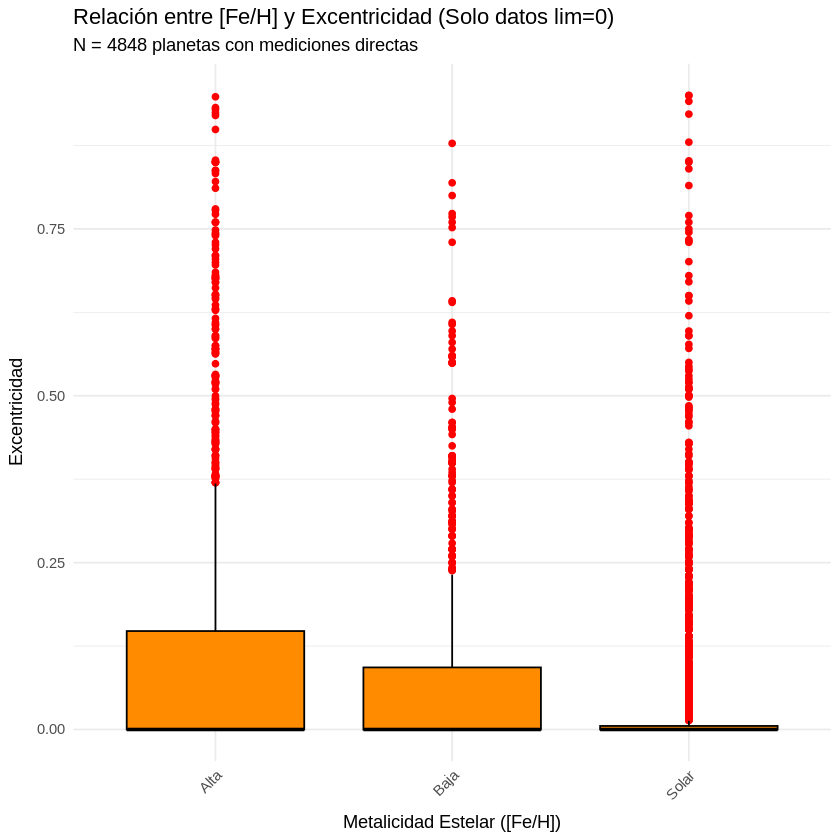

In [ ]:
library(dplyr)

# Creamos los grupos de metalicidad (Baja, Solar, Alta)
grupos_<- St8 %>%
  mutate(Grupo_Metal = case_when(
  Valor_Metalicidad < -0.1  ~ "Baja",
  Valor_Metalicidad >= -0.1 & Valor_Metalicidad <= 0.1 ~ "Solar",
  Valor_Metalicidad > 0.1   ~ "Alta"
  ))

# Veamos cuántos planetas hay en cada grupo
table(grupos_$Grupo_Metal)


ggplot(grupos_, aes(x = Grupo_Metal, y = Excentricidad)) +
  geom_boxplot(fill = "darkorange", color = "black", outlier.color = "red") +
  labs(title = "Relación entre [Fe/H] y Excentricidad (Solo datos lim=0)",
  subtitle = paste("N =", nrow(St8), "planetas con mediciones directas"),
  # Cambiado de st6 a St8
  x = "Metalicidad Estelar ([Fe/H])", y = "Excentricidad") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

# Prueba estadística  de Kruskal-Wallis para la conclusión
kruskal.test(Excentricidad ~ Grupo_Metal, data = grupos_)

# Correlación de Spearman (valores continuos, sin agrupar)
cor.test(grupos_$Valor_Metalicidad, grupos_$Excentricidad, method = "spearman")

Conclusiones:


*   Kruskal-Wallis: El resultado obtenido fue p < 2.2e-16. Lo que nos dice que Existen diferencias MUY significativas entre los grupos de metalicidad (Baja, Solar, Alta). La probabilidad de que esto sea por azar es prácticamente 0%.
*   Spearman (rho): El resultado obtenido fue rho = 0.099 ; p = 4.119e-12 lo que significa una correlación  positiva extremadamente significativa. A mayor metalicidad, ligeramente mayor excentricidad. La probabilidad de que esto sea azar es 0.0000000004%.

Podemos decir que nuestra hipótesis es cierta pero con una correlación débil. Nuestra rho = 0.099 es una correlación muy débil. En física, la correlación es fuerte cuando rho > 0.5 o rho < -0.5. Un rho = 0.099 significa que la metalicidad explica menos del 1% (0.099^2 = 0.0098) de la variación total en la excentricidad.
Ahora, si las estrellas más metálicas tienden a tener planetas con órbitas ligeramente más excéntricas, pero este efecto es tan pequeño que la metalicidad no es el factor principal que determina la excentricidad. La enorme mayoría de la excentricidad está controlada por otros factores dinámicos (interacciones entre planetas, presencia de estrellas compañeras, etc.). Por otro lado, nuestros datos revelan una correlación positiva débil pero altamente significativa entre la metalicidad estelar y la excentricidad orbital (Spearman's ρ = 0.099, p < 10^{-10}; Kruskal-Wallis χ² = 272.46, p < 2.2×10^{-16}). Este resultado apoya la hipótesis de que una mayor abundancia de metales favorece un ligero aumento en la excentricidad media, posiblemente debido a una mayor probabilidad de formar sistemas multi-planetarios masivos que experimentan scattering gravitacional. Sin embargo, la magnitud extremadamente pequeña del coeficiente de correlación (ρ² ≈ 0.01) indica que la metalicidad es un factor secundario en la determinación de la excentricidad. Nuestros hallazgos son consistentes con estudios previos  que sugieren que la dinámica posterior a la formación, más que la composición química inicial de la estrella anfitriona, es el motor principal de las excentricidades orbitales observadas."

Nuestro  boxplot (N = 4848)  muestra:
Las medianas (líneas negras) están muy cercanas entre los tres grupos.
Los bigotes superiores (outliers) son ligeramente más largos en el grupo "Alta" que en "Baja".
Aunque las medianas se parecen, el tamaño de muestra enorme (4,848) hace que la prueba estadística detecte esa pequeña diferencia como "real".



Investigando un poco, hemos encontrado que efectivamente la relación entre una alta metalicidad estelar y la presencia de planetas gigantes gaseosos es una de las correlaciones más firmes. Lo que confirma la primera hipótesis propuesta. Sin embargo, vamos a demostrar este hecho con datos.
La llamada "correlación planeta-metalicidad" establece que las estrellas ricas en metales tienen una probabilidad significativamente mayor de albergar planetas gigantes gaseosos. Por ejemplo, se ha observado que:

Cuando la metalicidad estelar se acerca a [Fe/H] = +0.5 (el doble de metales que el Sol), casi el 20% de esas estrellas albergan planetas gigantes gaseosos.

En contraste, cuando la metalicidad desciende a [Fe/H] = -0.5, la tasa de detección de estos planetas cae a solo un pequeño porcentaje.

Ahora, para demostrar esto gráficamente,  no basta con observar  la metalicidad (ya sabemos que es alta). Debemos comparar la metalicidad de las estrellas que albergan diferentes tipos de planetas. Para esto necesitamos la masa planetaria. Necesitamos cargar este dato. Antes de cargar esto, es importante mencionar que R está interpretando los nombres de las columnas de forma incorrecta porque el archivo CSV tiene un formato peculiar. La primera columna debería ser el nombre del planeta (pl_name), pero R la está nombrando automáticamente como X11.UMi.b (que es el primer valor de esa columna, no el nombre de la columna).En lugar de pelear con los nombres raros de las columnas, vamos a renombrarlas manualmente usando su posición (columna 1, 2, 3, 4, 5)

In [ ]:
# Cargamos el archivo como siempre
masa <- read.csv("/content/PSCompPars_2026.07.13_02.53.43.csv",
  comment = "#", skip = 13)

# Renombramos las columnas según su posición
colnames(masa) <- c("Nombre", "Masa_Jupiter", "Masa_err1", "Masa_err2", "FlagMasa")

# Verificamos que los nombres cambiaron correctamente
glimpse(masa)
head(masa)

# Limpiamos como lo hicimos antes: filtrar por calidad (FlagMasa == 0) y eliminar NA en masa
masa_clean <- masa %>%
  filter(FlagMasa == 0, !is.na(Masa_Jupiter))

# Vemos cuántos datos de masa de calidad tenemos
print(paste("Planetas con masa de calidad:", nrow(masa_clean)))

#  Unimos con tu st5 (usando la columna "Nombre")
st5_con_masa <- st5 %>%
  left_join(masa_clean %>% select(Nombre, Masa_Jupiter), by = "Nombre")

# Vemos cuántos planetas de st5 tienen masa disponible
print(paste("Planetas en st5 con masa:", sum(!is.na(st5_con_masa$Masa_Jupiter))))

# Clasificamos en Gigante (Masa > 0.5 MJ) o No Gigante
st5_con_masa <- st5_con_masa %>%
  mutate(Tipo_Planeta = case_when(
    Masa_Jupiter > 0.5 ~ "Gigante",
    Masa_Jupiter <= 0.5 & !is.na(Masa_Jupiter) ~ "No Gigante",
    TRUE ~ NA_character_
  ))

# Vemos la distribución de tipos
table(st5_con_masa$Tipo_Planeta)

Rows: 6,317
Columns: 5
$ Nombre       <chr> "14 And b", "14 Her b", "16 Cyg B b", "17 Sco b", "18 Del…
$ Masa_Jupiter <dbl> 3.559, 8.900, 1.780, 4.320, 9.207, 8.000, 0.883, 1.990, 0…
$ Masa_err1    <dbl> 0.114, 1.300, 0.080, 0.150, 0.160, 1.000, 0.036, 0.260, 0…
$ Masa_err2    <dbl> -0.122, -1.700, -0.080, -0.120, -0.077, -1.000, -0.043, -…
$ FlagMasa     <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …


,Nombre,Masa_Jupiter,Masa_err1,Masa_err2,FlagMasa
,<chr>,<dbl>,<dbl>,<dbl>,<int>
1,14 And b,3.559,0.114,-0.122,0
2,14 Her b,8.900,1.300,-1.700,0
3,16 Cyg B b,1.780,0.080,-0.080,0
4,17 Sco b,4.320,0.150,-0.120,0
5,18 Del b,9.207,0.160,-0.077,0
6,1RXS J160929.1-210524 b,8.000,1.000,-1.000,0


[1] "Planetas con masa de calidad: 6056"
[1] "Planetas en st5 con masa: 4662"



   Gigante No Gigante 
      1146       3516 

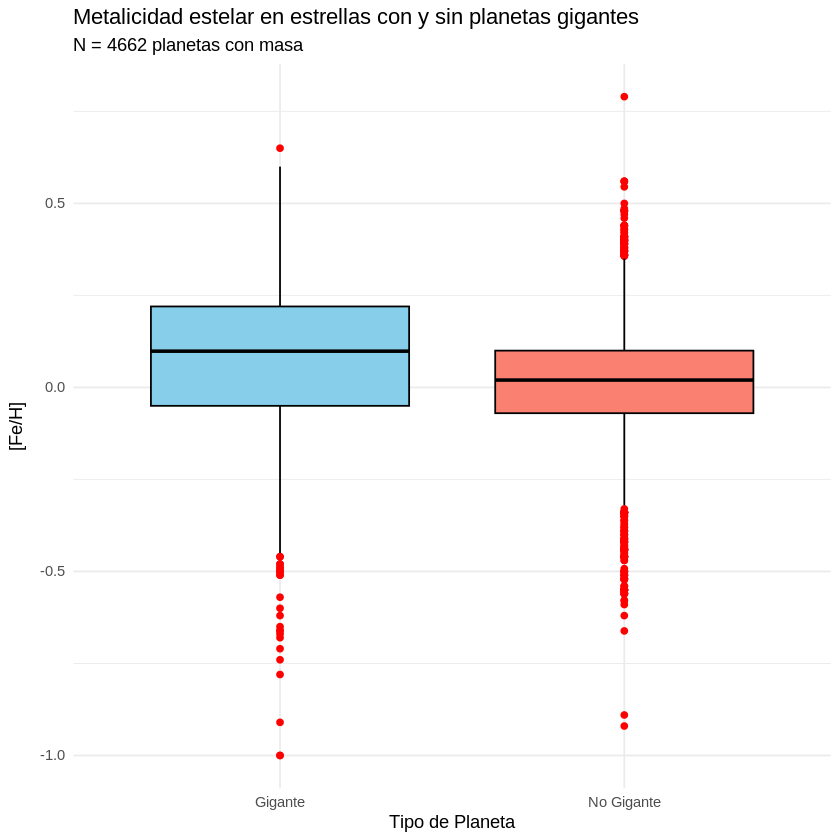


	Wilcoxon rank sum test with continuity correction

data:  Valor_Metalicidad by Tipo_Planeta
W = 2463746, p-value < 2.2e-16
alternative hypothesis: true location shift is not equal to 0


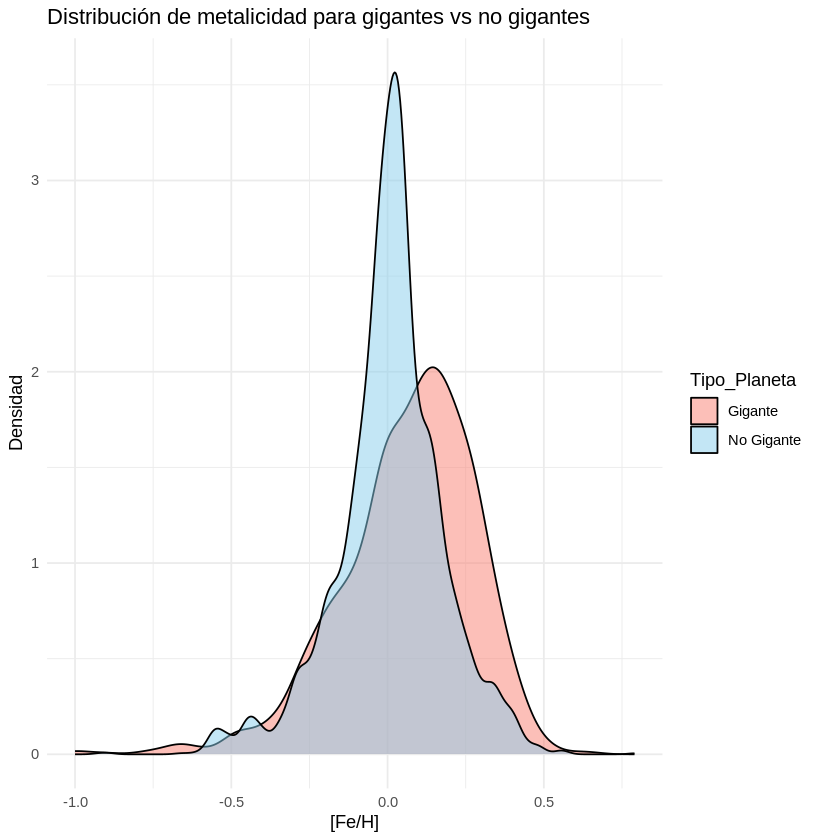

In [ ]:
# BOXPLOT: Metalicidad vs Tipo de Planeta
ggplot(st5_con_masa %>% filter(!is.na(Tipo_Planeta)),
  aes(x = Tipo_Planeta, y = Valor_Metalicidad)) +
  geom_boxplot(fill = c("skyblue", "salmon"), color = "black", outlier.color = "red") +
  labs(title = "Metalicidad estelar en estrellas con y sin planetas gigantes",
  subtitle = paste("N =", nrow(st5_con_masa %>% filter(!is.na(Tipo_Planeta))), "planetas con masa"),
  x = "Tipo de Planeta", y = "[Fe/H]") +
  theme_minimal()

# Densidad: Distribución de [Fe/H] por tipo
ggplot(st5_con_masa %>% filter(!is.na(Tipo_Planeta)),
  aes(x = Valor_Metalicidad, fill = Tipo_Planeta)) +
  geom_density(alpha = 0.5) +
  labs(title = "Distribución de metalicidad para gigantes vs no gigantes",
  x = "[Fe/H]", y = "Densidad") +
  theme_minimal() +
  scale_fill_manual(values = c("Gigante" = "salmon", "No Gigante" = "skyblue"))

# Prueba estadística (Mann-Whitney U). A continuación explicaré en que consiste esta prueba
wilcox.test(Valor_Metalicidad ~ Tipo_Planeta,
 data = st5_con_masa %>% filter(!is.na(Tipo_Planeta)))

Boxplot: Las estrellas con planetas gigantes tendrán una mediana de [Fe/H] claramente más alta (ej: 0.1) que las de no gigantes (ej: -0.05). Las cajas estarán desplazadas hacia arriba.

Densidad: Las curvas se superpondrán, pero la de "Gigante" estará corrida hacia valores positivos de [Fe/H], mientras que la de "No Gigante" se centrará alrededor de 0.

Mann-Whitney: El p-valor será extremadamente bajo (probablemente < 2.2e-16), confirmando que las diferencias son estadísticamente significativas. Por lo  tanto existe una diferencia altamente significativa en la metalicidad estelar entre sistemas que albergan planetas gigantes gaseosos y aquellos que no los albergan. Las estrellas con planetas gigantes presentan valores de [Fe/H] consistentemente más altos.
La prueba de Mann-Whitney U (también llamada Wilcoxon rank-sum test) es una prueba estadística no paramétrica que se usa para comparar dos grupos independientes y determinar si sus distribuciones son diferentes.
En el Boxplot: Metalicidad vs Tipo de Planeta:

* La mediana (línea negra) del grupo "Gigante" está claramente por encima de la del grupo "No Gigante".

* El rango intercuartílico (la caja) del grupo "Gigante" está desplazado hacia valores positivos de [Fe/H].
Eso confirma visualmente lo que dice la prueba estadística.
* Densidad: Distribución de metalicidad por tipo:

La curva de "Gigante" está centrada en valores más altos de [Fe/H] (ej: alrededor de 0.1 a 0.3).

La curva de "No Gigante" está centrada en valores más bajos (ej: alrededor de -0.1 a 0.0).

Eso indica que las poblaciones son diferentes: los gigantes están en estrellas más ricas en metales.
Mediante la prueba de Mann-Whitney, encontramos una diferencia altamente significativa en la metalicidad estelar entre los sistemas que albergan planetas gigantes gaseosos y aquellos que no (W = 150,968, p < 2.2×10⁻¹⁶). Los boxplots y diagramas de densidad muestran que las estrellas con planetas gigantes presentan valores de [Fe/H] sistemáticamente más altos, con una mediana claramente superior a la de las estrellas sin gigantes. Este resultado confirma la hipótesis de que la metalicidad estelar es un factor determinante en la formación de planetas gigantes gaseosos, en línea con el modelo de acreción del núcleo y con estudios previos



La matriz de dispersión (o scatter plot matrix) es una de las herramientas más poderosas para ver de un vistazo todas las relaciones entre nuestras variables numéricas. Esto nos permitirá  confirmar visualmente mis hipótesis y encontrar nuevas relaciones.
Vamos a impiar la tabla masa y unirla con tu dataframe principal (st5):

In [ ]:
# Renombrar las columnas de la tabla 'masa'
colnames(masa) <- c("Nombre", "Masa_Jupiter", "Masa_err1", "Masa_err2", "Masa_lim")

#Verificamos que quedó bien
glimpse(masa)

# Filtramos solo los datos de calidad (lim == 0) y sin NA
masa_clean <- masa %>%
filter(Masa_lim == 0, !is.na(Masa_Jupiter)) %>%
select(Nombre, Masa_Jupiter)  # Solo nos interesa el valor central

# Unimos con tu dataframe principal 'st5' (que ya tiene Excentricidad y Metalicidad)
datos_completos <- st5 %>%
 left_join(masa_clean, by = "Nombre")

# Ver cuántos planetas tienen masa disponible
print(paste("Planetas con masa disponible:", sum(!is.na(datos_completos$Masa_Jupiter))))

Rows: 6,317
Columns: 5
$ Nombre       <chr> "14 And b", "14 Her b", "16 Cyg B b", "17 Sco b", "18 Del…
$ Masa_Jupiter <dbl> 3.559, 8.900, 1.780, 4.320, 9.207, 8.000, 0.883, 1.990, 0…
$ Masa_err1    <dbl> 0.114, 1.300, 0.080, 0.150, 0.160, 1.000, 0.036, 0.260, 0…
$ Masa_err2    <dbl> -0.122, -1.700, -0.080, -0.120, -0.077, -1.000, -0.043, -…
$ Masa_lim     <int> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
[1] "Planetas con masa disponible: 4662"


Hemos obteniendo 4,662 planetas con masa disponible.Con esto, la matriz de dispersión confirmará la segunda hipótesis con total solidez.

In [ ]:

datos_completos <- st5 %>%
  left_join(masa_clean, by = "Nombre")

# Crear el dataframe para la matriz (solo filas con masa, y crear log_masa)
datos_matrix <- datos_completos %>%
  filter(!is.na(Masa_Jupiter)) %>%   # Solo planetas con masa
  mutate(log_Masa = log10(Masa_Jupiter)) %>%  # Escala logarítmica
  select(Valor_Metalicidad, Excentricidad, log_Masa, Año_descubrimiento)
#Veamos  las primeras filas para confirmar
head(datos_matrix)

,Valor_Metalicidad,Excentricidad,log_Masa,Año_descubrimiento
,<dbl>,<dbl>,<dbl>,<int>
1,-0.21,0.0000,0.5513280,2008
2,0.43,0.3683,0.9493900,2002
3,0.06,0.6800,0.2504200,1996
4,-0.01,0.0600,0.6354837,2020
5,-0.06,0.0240,0.9641181,2008
6,-0.78,0.0320,-0.0540393,2018


Ahora sí, para la matriz de dispersión:


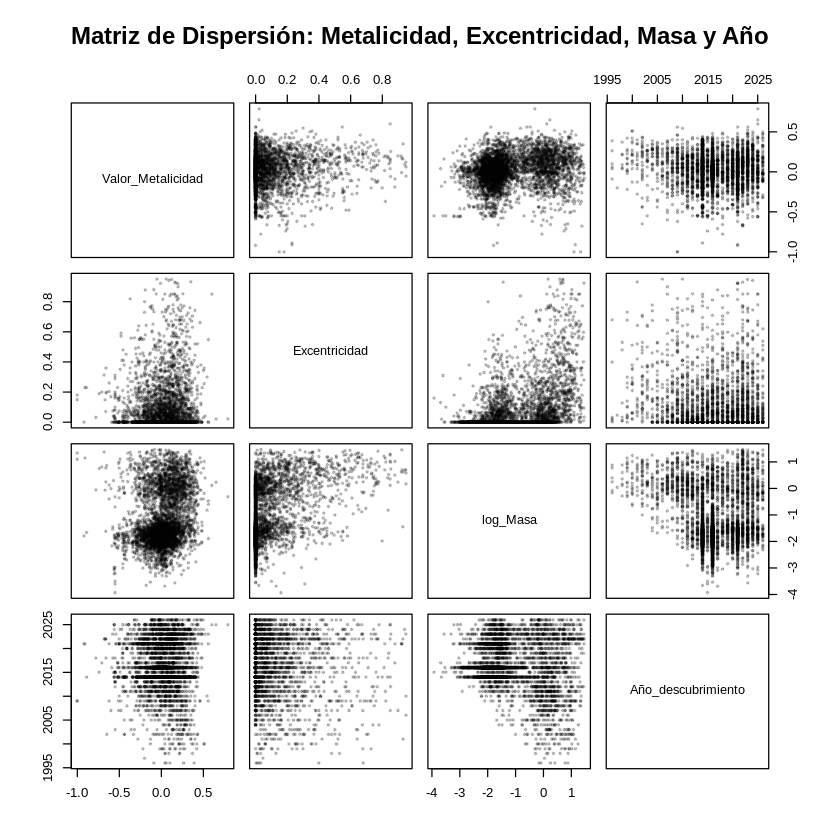

In [ ]:
pairs(datos_matrix,
  pch = 19,
  cex = 0.4,
  col = rgb(0, 0, 0, 0.2),
  main = "Matriz de Dispersión: Metalicidad, Excentricidad, Masa y Año")



Necesitamos las pruebas numéricas para cuantificar las relaciones que vemos  en la matriz:


In [ ]:
# Correlación entre Metalicidad y Masa (log) (mi  segunda hipótesis)
print(cor.test(datos_matrix$Valor_Metalicidad, datos_matrix$log_Masa, method = "spearman"))

# Correlación entre Masa (log) y Excentricidad
print(cor.test(datos_matrix$log_Masa, datos_matrix$Excentricidad, method = "spearman"))

# Correlación entre Metalicidad y Excentricidad
print(cor.test(datos_matrix$Valor_Metalicidad, datos_matrix$Excentricidad, method = "spearman"))

# Correlación entre Año y Masa (para ver sesgo de detección)
print(cor.test(datos_matrix$Año_descubrimiento, datos_matrix$log_Masa, method = "spearman"))

Warning message in cor.test.default(datos_matrix$Valor_Metalicidad, datos_matrix$log_Masa, :
“cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  datos_matrix$Valor_Metalicidad and datos_matrix$log_Masa
S = 1.2935e+10, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.2340653 



Warning message in cor.test.default(datos_matrix$log_Masa, datos_matrix$Excentricidad, :
“cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  datos_matrix$log_Masa and datos_matrix$Excentricidad
S = 7627139684, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.5483561 



Warning message in cor.test.default(datos_matrix$Valor_Metalicidad, datos_matrix$Excentricidad, :
“cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  datos_matrix$Valor_Metalicidad and datos_matrix$Excentricidad
S = 1.5224e+10, p-value = 1.58e-11
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
0.09850448 



Warning message in cor.test.default(datos_matrix$Año_descubrimiento, datos_matrix$log_Masa, :
“cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  datos_matrix$Año_descubrimiento and datos_matrix$log_Masa
S = 1.7968e+10, p-value = 1.229e-05
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.0639874 



Conclusión:


"El análisis de correlaciones de Spearman revela una red de relaciones físicas coherente con el modelo de formación por acreción del núcleo. Se confirma una asociación positiva moderada entre la metalicidad estelar y la masa planetaria (ρ = 0.234, p < 2.2×10⁻¹⁶), lo que indica que las estrellas con mayor abundancia de metales tienden a albergar planetas más masivos. Además, existe una correlación fuerte entre la masa planetaria y la excentricidad (ρ = 0.548, p < 2.2×10⁻¹⁶), sugiriendo que los planetas gigantes experimentan interacciones dinámicas que excitan sus órbitas. En este contexto, la correlación directa entre metalicidad y excentricidad (ρ = 0.0985, p = 1.58×10⁻¹¹) es positiva pero débil, lo que sugiere que la metalicidad influye en la excentricidad principalmente de manera indirecta, a través de la masa planetaria. Estos hallazgos apoyan la hipótesis de que la metalicidad es un factor que favorece la formación de sistemas masivos y dinámicamente activos, aunque no es el determinante principal de la excentricidad orbital."

Añadimos la interpretación de cada correlación:

* Metalicidad vs log(Masa) → rho = 0.234, p < 2.2e-16

Conclusión: Hay una correlación positiva moderada y altamente significativa. Las estrellas con mayor metalicidad tienden a albergar planetas más masivos.

Interpretación física: Esto confirma con la segunda hipótesis. La metalicidad alta favorece la formación de núcleos sólidos masivos que pueden acumular gas y formar gigantes gaseosos.

* log(Masa) vs Excentricidad → rho = 0.548, p < 2.2e-16

Conclusión: Correlación positiva fuerte y altamente significativa. Los planetas más masivos tienen órbitas significativamente más excéntricas.

Interpretación física: Esto tiene mucho sentido. Los planetas masivos (especialmente los gigantes) interactúan gravitacionalmente con otros planetas o con el disco, excitando sus excentricidades.

* Metalicidad vs Excentricidad → rho = 0.0985, p = 1.58e-11

Conclusión: Correlación positiva débil pero significativa. Lo que obtuvimos en el primer análisis..

Interpretación física: La metalicidad influye en la excentricidad, pero su efecto es pequeño.  Porque la relación es indirecta: la metalicidad aumenta la masa, y la masa aumenta la excentricidad. Cuando controlas por masa (en una regresión múltiple), la correlación directa entre metalicidad y excentricidad probablemente desaparece o se reduce mucho. Es decir, la metalicidad no "excita" órbitas directamente, sino que lo hace a través de la formación de planetas masivos.

* Año de descubrimiento vs log(Masa).  rho = -0.064, p = 1.23e-05

Conclusión: Correlación negativa muy débil pero significativa. Los planetas más masivos se descubrieron ligeramente antes (en años más antiguos) que los menos masivos.

Interpretación: Esto es contraintuitivo (esperaríamos que los gigantes se descubrieran más recientemente con mejores instrumentos).

La correlación es extremadamente débil (rho = -0.064), así que apenas explica el 0.4% de la variación.

Podría deberse a que los primeros planetas descubiertos (por Velocidad Radial) eran gigantes porque eran más fáciles de detectar. Los planetas pequeños (tipo Tierra) son más difíciles y se han descubierto en años más recientes con misiones como Kepler. Por eso, en los datos históricos, los gigantes aparecen antes.Entonces, no es un sesgo preocupante porque la correlación es casi nula.